# MARLEM issues, demonstrated one by one

Each section below runs the **original** code in `src_thesis/` on the smallest setup that shows one issue, and puts what the paper (or the code's own documented intent) says next to what the code does. A red **REPRODUCED** means the issue is present.

- The experiments live in [issue_demos.py](issue_demos.py), one function per issue; the code shown under each result is that function.
- [test_issue_demos.py](test_issue_demos.py) runs the same functions as acceptance tests (`expected == actual`), marked *xfail* while the issue exists. A fix turns one into XPASS, which fails the suite until the issue is closed in [issues.md](../issues.md).
- Issue text, code lines and status are in [issues.md](../issues.md); follow the issue link in each heading.

Run all cells with the `marlem` conda env (about 15 s).

In [1]:
import inspect, textwrap, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import issue_demos as D

results = {d.issue: d for d in D.run_all()}

def show(issue):
    d = results[issue]
    badge = "🔴 **REPRODUCED**" if d.reproduced else "🟢 not reproduced (fixed?)"
    fmt = lambda v: f"`{v}`"
    text = (f"{badge}\n\n| | |\n|---|---|\n| **Paper / intent** | {d.expected_label} |\n"
            f"| **Expected** | {fmt(d.expected)} |\n| **Actual** | {fmt(d.actual)} |\n")
    if d.note:
        text += f"\n{d.note}\n"
    src = textwrap.dedent(inspect.getsource(D.REGISTRY[issue].__wrapped__))
    text += f"\n<details><summary>Demo code</summary>\n\n```python\n{src}```\n</details>"
    display(Markdown(text))

## Overview

All demos, in validation-step order.

In [2]:
order = lambda i: (results[i].step[0], int(results[i].step[1:]), i)
overview = pd.DataFrame([{"issue": d.issue, "step": d.step, "title": d.title,
                          "expected": str(d.expected), "actual": str(d.actual),
                          "reproduced": "yes" if d.reproduced else "no"}
                         for d in (results[i] for i in sorted(results, key=order))])
print(f"{(overview.reproduced == 'yes').sum()} of {len(overview)} demos reproduce their issue")
overview

48 of 48 demos reproduce their issue


,issue,step,title,expected,actual,reproduced
0,I-01,A1,An episode runs 23 of 24 periods,24,23,yes
1,I-02,A1,The terminal flag never reaches the reward,3,0,yes
2,I-03,A1,reset(seed=None) replays the same episode,different,identical,yes
3,I-04,A1,env.seed() cannot be called,True,False,yes
4,I-78,A1,An invalid action crashes the step,step completes,ValueError,yes
5,I-05,A2,Profiles given to an agent are replaced at reset,"[10.0, 10.0, 10.0, 10.0, 10.0, 10.0]","[0.1, 0.1, 0.1, 0.1, 0.1, 5.0]",yes
6,I-08,A3,Order size does not follow eq. 15,75.0,45.0,yes
7,I-09,A3,α = 0.3 is sized as a buy but submitted as a sell,"('sell', 'sell')","('buy', 'sell')",yes
8,I-10,A3,β = 'no preference' is practically unreachable,0.2,0.0,yes
9,I-11,A3,An agent can never submit 'no order',0.0,0.1,yes


## How showable is each issue?

| Tier | Meaning |
|---|---|
| **demo** | A runnable experiment with a clear expected-vs-actual result (below). |
| **inspect** | A constant, default or formula; one line of code shows it, there is nothing to run. |
| **harness** | Needs a training or inference run (RLlib) to show. |
| **judgment** | A paper or documentation question; nothing in the code to execute. |

In [3]:
tiers = pd.DataFrame([{"issue": k, "tier": t, "why / what": r} for k, (t, r) in D.showability().items()])
display(tiers.tier.value_counts().rename("issues").to_frame().T)
tiers[tiers.tier != "demo"]

tier,demo,inspect,judgment,harness
issues,48,18,8,6


,issue,tier,why / what
5,I-06,inspect,Profile generation form and CSV column choice;...
21,I-22,inspect,No conservation identity exists; a demo can pr...
24,I-25,inspect,Two opposite sign conventions side by side in ...
28,I-29,inspect,F_trans is the literal 0.0
29,I-30,inspect,Caps 0.2 / 0.3 are literals
30,I-31,inspect,Follows from P2P impact 0 and DSO trades carry...
33,I-34,inspect,κ = 0.03 is a default argument
43,I-44,inspect,Follows from I-24: every term multiplied by ds...
45,I-46,inspect,p_dso vs p_no_trades in the penalty formula
47,I-48,harness,Needs one RLlib update of the CTDE module to s...


## Stage A · Level 0, Platform Marketplace

### A1. Episode loop

#### [I-01](../issues.md#I-01) · An episode runs 23 of 24 periods

In [4]:
show("I-01")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | steps per episode with max_steps = 24 |
| **Expected** | `24` |
| **Actual** | `23` |

<details><summary>Demo code</summary>

```python
@demo(
    "I-01",
    "A1",
    "An episode runs 23 of 24 periods",
    "steps per episode with max_steps = 24",
)
def i01():
    return 24, run_episode(make_env())
```
</details>

#### [I-02](../issues.md#I-02) · The terminal flag never reaches the reward

In [5]:
show("I-02")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | reward calls with is_terminal=True per episode (one per agent at the last step) |
| **Expected** | `3` |
| **Actual** | `0` |

<details><summary>Demo code</summary>

```python
@demo(
    "I-02",
    "A1",
    "The terminal flag never reaches the reward",
    "reward calls with is_terminal=True per episode (one per agent at the last step)",
)
def i02():
    env = make_env()
    seen = []
    orig = env.reward_handler.calculate_reward

    def spy(*a, **kw):
        seen.append(kw.get("is_terminal", False))
        return orig(*a, **kw)

    env.reward_handler.calculate_reward = spy
    run_episode(env)
    return len(env.agents_id), sum(seen)
```
</details>

#### [I-03](../issues.md#I-03) · reset(seed=None) replays the same episode

In [6]:
show("I-03")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | two resets without a seed give different episodes |
| **Expected** | `different` |
| **Actual** | `identical` |

The configured seed 7 is reused on every reset, so a training run sees one episode over and over.

<details><summary>Demo code</summary>

```python
@demo(
    "I-03",
    "A1",
    "reset(seed=None) replays the same episode",
    "two resets without a seed give different episodes",
)
def i03():
    env = make_env(seed=7)
    env.reset()
    first = list(env._agents["a0"].generation_profile)
    env.reset()
    second = list(env._agents["a0"].generation_profile)
    return (
        "different",
        "identical" if first == second else "different",
        "The configured seed 7 is reused on every reset, so a training run sees one "
        "episode over and over.",
    )
```
</details>

#### [I-04](../issues.md#I-04) · env.seed() cannot be called

In [7]:
show("I-04")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | env.seed is callable |
| **Expected** | `True` |
| **Actual** | `False` |

env.seed is 7: the attribute set in __init__ shadows the method.

<details><summary>Demo code</summary>

```python
@demo("I-04", "A1", "env.seed() cannot be called", "env.seed is callable")
def i04():
    env = make_env()
    return (
        True,
        callable(env.seed),
        f"env.seed is {env.seed!r}: the attribute set in __init__ shadows the method.",
    )
```
</details>

#### [I-78](../issues.md#I-78) · An invalid action crashes the step

In [8]:
show("I-78")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | Alg. 1 drops the invalid order and the step completes |
| **Expected** | `step completes` |
| **Actual** | `ValueError` |

Invalid action for a0: [100.          1.8476684   1.         99.       ]

<details><summary>Demo code</summary>

```python
@demo(
    "I-78",
    "A1",
    "An invalid action crashes the step",
    "Alg. 1 drops the invalid order and the step completes",
)
def i78():
    env = make_env()
    env.reset(seed=7)
    acts = {aid: env.action_spaces[aid].sample() for aid in env.agents_id}
    acts["a0"] = np.array(
        [100.0, 5.0, 1.0, 99.0], dtype=np.float32
    )  # partner index 99 is outside the space
    try:
        env.step(acts)
        return "step completes", "step completes"
    except ValueError as e:
        return "step completes", "ValueError", str(e)
```
</details>

### A2. Inputs: profiles and units

#### [I-05](../issues.md#I-05) · Profiles given to an agent are replaced at reset

In [9]:
show("I-05")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | agent a0 keeps its configured generation profile (10 kWh every period) |
| **Expected** | `[10.0, 10.0, 10.0, 10.0, 10.0, 10.0]` |
| **Actual** | `[0.1, 0.1, 0.1, 0.1, 0.1, 5.0]` |

First 6 of 24 periods. The profile handler regenerates every agent's profiles on each reset.

<details><summary>Demo code</summary>

```python
@demo(
    "I-05",
    "A2",
    "Profiles given to an agent are replaced at reset",
    "agent a0 keeps its configured generation profile (10 kWh every period)",
)
def i05():
    env = make_env()
    env.reset(seed=7)
    g = env._agents["a0"].generation_profile
    return (
        [10.0] * 6,
        [round(float(x), 1) for x in g[:6]],
        "First 6 of 24 periods. The profile handler regenerates every agent's "
        "profiles on each reset.",
    )
```
</details>

### A3. Action → order

#### [I-08](../issues.md#I-08) · Order size does not follow eq. 15

In [10]:
show("I-08")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | q_buy,max = max(0, D − G) + (SoC_max − SoC)·C = 25 + 50 = 75 |
| **Expected** | `75.0` |
| **Actual** | `45.0` |

Request: buy 100 with G = 5, D = 30, 50 kWh free in the battery. The code subtracts G and a discharge from the *request*.

<details><summary>Demo code</summary>

```python
@demo(
    "I-08",
    "A3",
    "Order size does not follow eq. 15",
    "q_buy,max = max(0, D − G) + (SoC_max − SoC)·C = 25 + 50 = 75",
)
def i08():
    bat = Battery(100, 0.0, 1.0, 1.0, 1.0)
    bat.energy_level = 50.0
    ag = DERAgent(
        "t", 60.0, battery=bat, generation_profile=[5.0], demand_profile=[30.0]
    )
    adj = ag.adjust_action_for_battery(
        0, np.array([100.0, 100.0, 1.0, 0.0]), market_config()
    )
    return (
        75.0,
        float(adj[1]),
        "Request: buy 100 with G = 5, D = 30, 50 kWh free in the battery. The code "
        "subtracts G and a discharge from the *request*.",
    )
```
</details>

#### [I-09](../issues.md#I-09) · α = 0.3 is sized as a buy but submitted as a sell

In [11]:
show("I-09")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | direction used for sizing = direction submitted |
| **Expected** | `('sell', 'sell')` |
| **Actual** | `('buy', 'sell')` |

The agent (deficit of 25 kWh) submits a *sell* order of 35.0 kWh.

<details><summary>Demo code</summary>

```python
@demo(
    "I-09",
    "A3",
    "α = 0.3 is sized as a buy but submitted as a sell",
    "direction used for sizing = direction submitted",
)
def i09():
    ag = DERAgent("u", 60.0, generation_profile=[5.0], demand_profile=[30.0])
    adj = ag.adjust_action_for_battery(
        0, np.array([100.0, 40.0, 0.3, 0.0]), market_config()
    )
    sized = (
        "buy" if adj[2] else "sell"
    )  # adjust_action_for_battery: `if is_buy:` (truthy)
    submitted = (
        "buy" if adj[2] > 0.5 else "sell"
    )  # LocalEnergyMarket.step: `is_buy > 0.5`
    return (
        ("sell", "sell"),
        (sized, submitted),
        f"The agent (deficit of 25 kWh) submits a *sell* order of {adj[1]:.1f} kWh.",
    )
```
</details>

#### [I-10](../issues.md#I-10) · β = 'no preference' is practically unreachable

In [12]:
show("I-10")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | share of uniformly sampled β that means 'no preference' (1 of N + 2 choices) |
| **Expected** | `0.2` |
| **Actual** | `0.0` |

int(β) equals N + 1 only when β hits the upper bound exactly.

<details><summary>Demo code</summary>

```python
@demo(
    "I-10",
    "A3",
    "β = 'no preference' is practically unreachable",
    "share of uniformly sampled β that means 'no preference' (1 of N + 2 choices)",
)
def i10():
    n = 3
    beta = np.random.default_rng(0).uniform(0, n + 1, 100_000)
    share = float(np.mean(beta.astype(int) == n + 1))
    return (
        round(1 / (n + 2), 3),
        round(share, 3),
        "int(β) equals N + 1 only when β hits the upper bound exactly.",
    )
```
</details>

#### [I-11](../issues.md#I-11) · An agent can never submit 'no order'

In [13]:
show("I-11")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | quantity after clipping when the policy asks for 0 |
| **Expected** | `0.0` |
| **Actual** | `0.1` |

With q_min > 0 every agent trades every period; the paper has no no-trade action.

<details><summary>Demo code</summary>

```python
@demo(
    "I-11",
    "A3",
    "An agent can never submit 'no order'",
    "quantity after clipping when the policy asks for 0",
)
def i11():
    ag = DERAgent("v", 60.0, generation_profile=[20.0], demand_profile=[20.0])
    adj = ag.adjust_action_for_battery(
        0, np.array([100.0, 0.0, 1.0, 0.0]), market_config(min_quantity=0.1)
    )
    return (
        0.0,
        round(float(adj[1]), 3),
        "With q_min > 0 every agent trades every period; the paper has no no-trade "
        "action.",
    )
```
</details>

#### [I-77](../issues.md#I-77) · Rule-based partner choice is random

In [14]:
show("I-77")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | distinct partners chosen in 50 calls with an unchanged state (a weighted score picks one) |
| **Expected** | `1` |
| **Actual** | `2` |

Picked: ['a2', 'a3']

<details><summary>Demo code</summary>

```python
@demo(
    "I-77",
    "A3",
    "Rule-based partner choice is random",
    "distinct partners chosen in 50 calls with an unchanged state (a weighted score "
    "picks one)",
)
def i77():
    env = make_env(n=4)
    env.reset(seed=7)
    a0 = env._agents["a0"]
    picks = {
        a0.select_preferred_partner(
            [*env._agents.values()], env.grid_network.graph, randomize=True
        )
        for _ in range(50)
    }
    return 1, len(picks), f"Picked: {sorted(picks)}"
```
</details>

### A4. Pricing

#### [I-13](../issues.md#I-13) · Pay-as-bid (seller) returns the buyer's price

In [15]:
show("I-13")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | trade price = p_sell = 50 (buy 200, sell 50) |
| **Expected** | `50.0` |
| **Actual** | `200.0` |

The matcher passes (buy, sell, market_price); SellerPricing's first parameter is named sell_order.

<details><summary>Demo code</summary>

```python
@demo(
    "I-13",
    "A4",
    "Pay-as-bid (seller) returns the buyer's price",
    "trade price = p_sell = 50 (buy 200, sell 50)",
)
def i13():
    b, s = order("b", 200.0, 1.0, True), order("s", 50.0, 1.0, False)
    return (
        50.0,
        ClearingMechanism.SELLER.get_instance().calculate_price(b, s, 100.0),
        "The matcher passes (buy, sell, market_price); SellerPricing's first "
        "parameter is named sell_order.",
    )
```
</details>

#### [I-17](../issues.md#I-17) · Bid-ask spread pricing returns the buyer's price

In [16]:
show("I-17")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | p_sell + factor·(p_buy − p_sell) with the default factor 0.5 = 125 |
| **Expected** | `125.0` |
| **Actual** | `200.0` |

market_price = 100 lands in `factor` and is clipped to 1. [P1] Case 5 uses this mechanism.

<details><summary>Demo code</summary>

```python
@demo(
    "I-17",
    "A4",
    "Bid-ask spread pricing returns the buyer's price",
    "p_sell + factor·(p_buy − p_sell) with the default factor 0.5 = 125",
)
def i17():
    b, s = order("b", 200.0, 1.0, True), order("s", 50.0, 1.0, False)
    return (
        125.0,
        ClearingMechanism.BID_ASK_SPREAD.get_instance().calculate_price(b, s, 100.0),
        "market_price = 100 lands in `factor` and is clipped to 1. [P1] Case 5 uses "
        "this mechanism.",
    )
```
</details>

### A5. Matching

#### [I-12](../issues.md#I-12) · Matching overwrites the submitted order

In [17]:
show("I-12")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | order.quantity after matching = submitted 10 |
| **Expected** | `10.0` |
| **Actual** | `0.0` |

The reward, KPIs and info read this field after matching.

<details><summary>Demo code</summary>

```python
@demo(
    "I-12",
    "A5",
    "Matching overwrites the submitted order",
    "order.quantity after matching = submitted 10",
)
def i12():
    m, *_ = matcher()
    b = order("a0", 200.0, 10.0, True)
    m.match_orders(0, [b, order("a1", 50.0, 10.0, False)], {}, 0.0)
    return 10.0, b.quantity, "The reward, KPIs and info read this field after matching."
```
</details>

#### [I-14](../issues.md#I-14) · The P2P loss is bought again from the DSO

In [18]:
show("I-14")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | energy the buyer is billed for = 10 (paper: the loss derates what is delivered) |
| **Expected** | `10.0` |
| **Actual** | `10.7912` |

P2P loss 0.791 kWh is re-bought from the DSO at the utility price.

<details><summary>Demo code</summary>

```python
@demo(
    "I-14",
    "A5",
    "The P2P loss is bought again from the DSO",
    "energy the buyer is billed for = 10 (paper: the loss derates what is delivered)",
)
def i14():
    m, grid, dso, locs = matcher(located=True)
    res = m.match_orders(
        0,
        [order("a0", 200.0, 10.0, True, locs), order("a1", 50.0, 10.0, False, locs)],
        {},
        0.0,
    )
    bought = sum(t.quantity for t in res.trades if t.buyer_id == "a0")
    loss = sum(t.transmission_loss for t in res.trades)
    return (
        10.0,
        round(bought, 4),
        f"P2P loss {loss:.3f} kWh is re-bought from the DSO at the utility price.",
        {
            "trades": [
                (t.seller_id, t.buyer_id, t.quantity, t.price) for t in res.trades
            ]
        },
    )
```
</details>

#### [I-15](../issues.md#I-15) · Stage 1 sends DSO-preferred orders to the DSO first

In [19]:
show("I-15")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | a buyer at 200 and a seller at 50 trade P2P (only mutual preferences go first) |
| **Expected** | `['P2P']` |
| **Actual** | `['DSO', 'DSO']` |

Both sides trade with the DSO at its tariffs although a P2P match at 125 was available.

<details><summary>Demo code</summary>

```python
@demo(
    "I-15",
    "A5",
    "Stage 1 sends DSO-preferred orders to the DSO first",
    "a buyer at 200 and a seller at 50 trade P2P (only mutual preferences go first)",
)
def i15():
    m, *_ = matcher()
    res = m.match_orders(
        0,
        [order("a0", 200.0, 10.0, True, partner="DSO"), order("a1", 50.0, 10.0, False)],
        {},
        0.0,
    )
    kinds = sorted(
        "P2P" if "DSO" not in (t.buyer_id, t.seller_id) else "DSO" for t in res.trades
    )
    return (
        ["P2P"],
        kinds,
        "Both sides trade with the DSO at its tariffs although a P2P match at 125 "
        "was available.",
    )
```
</details>

#### [I-16](../issues.md#I-16) · The clearing price mixes P2P and DSO trades

In [20]:
show("I-16")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | clearing price = the P2P price 125 |
| **Expected** | `125.0` |
| **Actual** | `187.5` |

10 kWh P2P at 125 plus 10 kWh from the DSO at 250 → volume-weighted 187.5.

<details><summary>Demo code</summary>

```python
@demo(
    "I-16",
    "A5",
    "The clearing price mixes P2P and DSO trades",
    "clearing price = the P2P price 125",
)
def i16():
    m, *_ = matcher()
    res = m.match_orders(
        0, [order("a0", 200.0, 20.0, True), order("a1", 50.0, 10.0, False)], {}, 0.0
    )
    return (
        125.0,
        res.clearing_price,
        "10 kWh P2P at 125 plus 10 kWh from the DSO at 250 → volume-weighted 187.5.",
    )
```
</details>

#### [I-54](../issues.md#I-54) · DSO trades skip all grid terms

In [21]:
show("I-54")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | fees on a DSO trade of the same seller > 0 (the grid is used either way) |
| **Expected** | `fees > 0` |
| **Actual** | `0 (distance, loss, fee all 0)` |

The same 10 kWh sold P2P carries fees 275.15; sold to the DSO: distance 0.0, loss 0.0, fees 0.0.

<details><summary>Demo code</summary>

```python
@demo(
    "I-54",
    "A5",
    "DSO trades skip all grid terms",
    "fees on a DSO trade of the same seller > 0 (the grid is used either way)",
)
def i54():
    m, grid, dso, locs = matcher(located=True)
    p2p = m.match_orders(
        0,
        [order("a0", 200.0, 10.0, True, locs), order("a1", 50.0, 10.0, False, locs)],
        {},
        0.0,
    )
    m2, _, _, locs2 = matcher(located=True)
    only = m2.match_orders(0, [order("a1", 50.0, 10.0, False, locs2)], {}, 0.0)
    t_dso = only.trades[0]
    p2p_fee = next(t.fees for t in p2p.trades if "DSO" not in (t.buyer_id, t.seller_id))
    return (
        "fees > 0",
        "fees > 0" if t_dso.fees > 0 else "0 (distance, loss, fee all 0)",
        f"The same 10 kWh sold P2P carries fees {p2p_fee:.2f}; sold to the DSO: "
        f"distance {t_dso.distance}, loss {t_dso.transmission_loss}, fees "
        f"{t_dso.fees}.",
    )
```
</details>

#### [I-55](../issues.md#I-55) · The Stage-2 capacity limit is not the grid capacity

In [22]:
show("I-55")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | capacity used by the Stage-2 check = grid capacity 300 |
| **Expected** | `300.0` |
| **Actual** | `200.0` |

The matcher uses max_quantity · N = 100 · 2.

<details><summary>Demo code</summary>

```python
@demo(
    "I-55",
    "A5",
    "The Stage-2 capacity limit is not the grid capacity",
    "capacity used by the Stage-2 check = grid capacity 300",
)
def i55():
    m, grid, *_ = matcher()
    return (
        grid.capacity,
        m.grid_capacity,
        "The matcher uses max_quantity · N = 100 · 2.",
    )
```
</details>

### A6. DSO: balance and fees

#### [I-24](../issues.md#I-24) · The DSO balance ignores Stage-3 DSO trades

In [23]:
show("I-24")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | |B_DSO| after the DSO buys 10 kWh (eq. 7) |
| **Expected** | `10.0` |
| **Actual** | `0.0` |

The balance only moves for Stage-1 DSO-preferred orders, so it stays 0 by default (T4).

<details><summary>Demo code</summary>

```python
@demo(
    "I-24",
    "A6",
    "The DSO balance ignores Stage-3 DSO trades",
    "|B_DSO| after the DSO buys 10 kWh (eq. 7)",
)
def i24():
    m, _, dso, _ = matcher()
    m.match_orders(0, [order("a1", 50.0, 10.0, False)], {}, 0.0)
    return (
        10.0,
        abs(dso.balance),
        "The balance only moves for Stage-1 DSO-preferred orders, so it stays 0 by "
        "default (T4).",
    )
```
</details>

#### [I-28](../issues.md#I-28) · Grid fees are never charged

In [24]:
show("I-28")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | DSO profit includes the fees it computed |
| **Expected** | `472.9617` |
| **Actual** | `197.8096` |

Fees of 275.15 are stored on the trade and summed in dso.fees, but nobody pays them.

<details><summary>Demo code</summary>

```python
@demo(
    "I-28",
    "A6",
    "Grid fees are never charged",
    "DSO profit includes the fees it computed",
)
def i28():
    m, _, dso, locs = matcher(located=True)
    res = m.match_orders(
        0,
        [order("a0", 200.0, 10.0, True, locs), order("a1", 50.0, 10.0, False, locs)],
        {},
        0.0,
    )
    fees = sum(t.fees for t in res.trades)
    dso_margin = sum(
        t.quantity * t.price for t in res.trades if t.seller_id == "DSO"
    ) - sum(t.quantity * t.price for t in res.trades if t.buyer_id == "DSO")
    return (
        round(dso_margin + fees, 4),
        round(dso.profit, 4),
        f"Fees of {fees:.2f} are stored on the trade and summed in dso.fees, but "
        "nobody pays them.",
    )
```
</details>

### A7. Grid

#### [I-32](../issues.md#I-32) · Stage-2 trades do not load the grid

In [25]:
show("I-32")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | edge flow added by a 10 kWh P2P trade across the line (> 0) |
| **Expected** | `> 0` |
| **Actual** | `0.0` |

<details><summary>Demo code</summary>

```python
@demo(
    "I-32",
    "A7",
    "Stage-2 trades do not load the grid",
    "edge flow added by a 10 kWh P2P trade across the line (> 0)",
)
def i32():
    m, grid, _, locs = matcher(located=True)
    before = sum(grid.edge_flows.values())
    m.match_orders(
        0,
        [order("a0", 200.0, 10.0, True, locs), order("a1", 50.0, 10.0, False, locs)],
        {},
        0.0,
    )
    return "> 0", "> 0" if sum(grid.edge_flows.values()) - before > 1e-9 else "0.0"
```
</details>

#### [I-33](../issues.md#I-33) · The grid starts every episode already loaded

In [26]:
show("I-33")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | mean congestion before any trade (flows are per period) |
| **Expected** | `0.0` |
| **Actual** | `0.1137` |

Flows start at U(0, 0.3)·capacity and only accumulate; congestion never decreases within an episode (T10).

<details><summary>Demo code</summary>

```python
@demo(
    "I-33",
    "A7",
    "The grid starts every episode already loaded",
    "mean congestion before any trade (flows are per period)",
)
def i33():
    grid = GridNetwork(GridTopology.MESH, 3, 300.0, seed=1)
    cong = []
    env = make_env()
    run_episode(env, on_step=lambda e, _: cong.append(round(e.dso.congestion_level, 4)))
    return (
        0.0,
        round(grid.calculate_congestion_level(), 4),
        "Flows start at U(0, 0.3)·capacity and only accumulate; congestion never "
        "decreases within an episode (T10).",
        {"congestion_per_step": cong},
    )
```
</details>

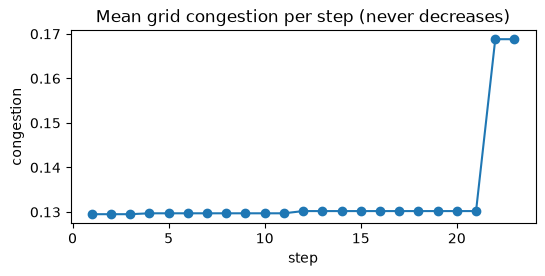

In [27]:
c = results["I-33"].details["congestion_per_step"]
plt.figure(figsize=(6, 2.5)); plt.plot(range(1, len(c) + 1), c, marker="o")
plt.title("Mean grid congestion per step (never decreases)"); plt.xlabel("step"); plt.ylabel("congestion"); plt.show()

#### [I-57](../issues.md#I-57) · The IEEE-34 feeder is disconnected

In [28]:
show("I-57")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | IEEE-34 graph is connected |
| **Expected** | `True` |
| **Actual** | `False` |

Island: [['888', '890']] (edge 832–888 is missing).

<details><summary>Demo code</summary>

```python
@demo("I-57", "A7", "The IEEE-34 feeder is disconnected", "IEEE-34 graph is connected")
def i57():
    import networkx as nx

    g = GridNetwork(GridTopology.IEEE34, capacity=1800.0, seed=1).graph
    islands = [sorted(c) for c in nx.connected_components(g) if len(c) < 5]
    return True, nx.is_connected(g), f"Island: {islands} (edge 832–888 is missing)."
```
</details>

#### [I-70](../issues.md#I-70) · Losses can exceed the energy sent

In [29]:
show("I-70")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | loss of a 10 kWh transfer over distance 40 ≤ 10 |
| **Expected** | `≤ 10` |
| **Actual** | `12.0` |

Loss = d · q · 0.03 is linear and unbounded once d · κ > 1.

<details><summary>Demo code</summary>

```python
@demo(
    "I-70",
    "A7",
    "Losses can exceed the energy sent",
    "loss of a 10 kWh transfer over distance 40 ≤ 10",
)
def i70():
    grid = GridNetwork(GridTopology.MESH, 3, 300.0, seed=1)
    loss = grid.transmission_loss(40.0, 10.0)
    return (
        "≤ 10",
        "≤ 10" if loss <= 10 else f"{loss:.1f}",
        "Loss = d · q · 0.03 is linear and unbounded once d · κ > 1.",
    )
```
</details>

### A8. Settlement: energy and cash

#### [I-18](../issues.md#I-18) · Selling energy charges the battery

In [30]:
show("I-18")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | battery level after selling 10 kWh with G = D (start 50, η = 1) |
| **Expected** | `40.0` |
| **Actual** | `60.0` |

The trade term enters with the wrong sign (T7).

<details><summary>Demo code</summary>

```python
@demo(
    "I-18",
    "A8",
    "Selling energy charges the battery",
    "battery level after selling 10 kWh with G = D (start 50, η = 1)",
)
def i18():
    bat = Battery(100, 0.0, 1.0, 1.0, 1.0)
    bat.energy_level = 50.0
    ag = DERAgent(
        "t", 50.0, battery=bat, generation_profile=[20.0], demand_profile=[20.0]
    )
    ag.update_battery_from_trades(0, energy_bought=0.0, energy_sold=10.0)
    return (
        40.0,
        ag.battery.energy_level,
        "The trade term enters with the wrong sign (T7).",
    )
```
</details>

#### [I-19](../issues.md#I-19) · A charge that would fill the battery is refused

In [31]:
show("I-19")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | energy level after charging 10 kWh at 95 of 100 kWh (partial fill to 100) |
| **Expected** | `100.0` |
| **Actual** | `95.0` |

<details><summary>Demo code</summary>

```python
@demo(
    "I-19",
    "A8",
    "A charge that would fill the battery is refused",
    "energy level after charging 10 kWh at 95 of 100 kWh (partial fill to 100)",
)
def i19():
    bat = Battery(100, 0.0, 1.0, 1.0, 1.0)
    bat.energy_level = 95.0
    bat.charge(10.0)
    return 100.0, bat.energy_level
```
</details>

#### [I-20](../issues.md#I-20) · Discharge efficiency points the wrong way

In [32]:
show("I-20")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | stored energy after delivering 9 kWh with η = 0.9 from 50 (eq. 16: E − E_out/η = 40) |
| **Expected** | `40.0` |
| **Actual** | `41.9` |

Storage drops by E_out·η, so discharging creates energy.

<details><summary>Demo code</summary>

```python
@demo(
    "I-20",
    "A8",
    "Discharge efficiency points the wrong way",
    "stored energy after delivering 9 kWh with η = 0.9 from 50 (eq. 16: E − E_out/η "
    "= 40)",
)
def i20():
    bat = Battery(100, 0.0, 1.0, 1.0, 0.9)
    bat.energy_level = 50.0
    bat.discharge(9.0)
    return (
        40.0,
        round(bat.energy_level, 4),
        "Storage drops by E_out·η, so discharging creates energy.",
    )
```
</details>

#### [I-21](../issues.md#I-21) · Demand served from the battery is not counted

In [33]:
show("I-21")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | demand satisfied when G = 10, D = 20 and the battery covers the other 10 |
| **Expected** | `20.0` |
| **Actual** | `10.0` |

Battery went 50 → 40; the 10 kWh is recorded as deferred demand.

<details><summary>Demo code</summary>

```python
@demo(
    "I-21",
    "A8",
    "Demand served from the battery is not counted",
    "demand satisfied when G = 10, D = 20 and the battery covers the other 10",
)
def i21():
    bat = Battery(100, 0.0, 1.0, 1.0, 1.0)
    bat.energy_level = 50.0
    ag = DERAgent(
        "w", 60.0, battery=bat, generation_profile=[10.0], demand_profile=[20.0]
    )
    ag.update_battery_from_trades(0, 0.0, 0.0)  # discharges 10
    ag.update_energy_tracking(0, 0.0, 0.0)
    return (
        20.0,
        ag.cumulative_demand_satisfied,
        f"Battery went 50 → {bat.energy_level:.0f}; the 10 kWh is recorded as "
        "deferred demand.",
    )
```
</details>

#### [I-23](../issues.md#I-23) · The grid balance signal is not eq. 20

In [34]:
show("I-23")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | grid balance = Σ_i (G − D + bought − sold) for the step |
| **Expected** | `-101.96099853515625` |
| **Actual** | `0.0` |

The observation and info use dso.balance, which stays 0 (I-24).

<details><summary>Demo code</summary>

```python
@demo(
    "I-23",
    "A8",
    "The grid balance signal is not eq. 20",
    "grid balance = Σ_i (G − D + bought − sold) for the step",
)
def i23():
    env = make_env()
    env.reset(seed=7)
    for i, aid in enumerate(env.agents_id):
        env.action_spaces[aid].seed(i)
    step = env.current_step
    _, _, _, _, info = env.step(
        {aid: env.action_spaces[aid].sample() for aid in env.agents_id}
    )
    trades = info["a0"]["trades"]
    b_grid = sum(
        a.get_generation(step)
        - a.get_demand(step)
        + sum(t.quantity for t in trades if t.buyer_id == a.id)
        - sum(t.quantity for t in trades if t.seller_id == a.id)
        for a in env._agents.values()
    )
    return (
        round(b_grid, 3),
        round(info["a0"]["grid_balance"], 3),
        "The observation and info use dso.balance, which stays 0 (I-24).",
    )
```
</details>

#### [I-26](../issues.md#I-26) · The agent balance is not eq. 13

In [35]:
show("I-26")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | agent balance = (G − D) + (bought − sold) |
| **Expected** | `-29.70800018310547` |
| **Actual** | `13.107999801635742` |

The code stores sold − bought: no G, no D, opposite sign.

<details><summary>Demo code</summary>

```python
@demo(
    "I-26",
    "A8",
    "The agent balance is not eq. 13",
    "agent balance = (G − D) + (bought − sold)",
)
def i26():
    env = make_env()
    env.reset(seed=7)
    for i, aid in enumerate(env.agents_id):
        env.action_spaces[aid].seed(i)
    step = env.current_step
    _, _, _, _, info = env.step(
        {aid: env.action_spaces[aid].sample() for aid in env.agents_id}
    )
    a = env._agents["a0"]
    trades = info["a0"]["trades"]
    bought = sum(t.quantity for t in trades if t.buyer_id == "a0")
    sold = sum(t.quantity for t in trades if t.seller_id == "a0")
    return (
        round(a.get_generation(step) - a.get_demand(step) + bought - sold, 3),
        round(a.balance, 3),
        "The code stores sold − bought: no G, no D, opposite sign.",
    )
```
</details>

#### [I-27](../issues.md#I-27) · Profit is never updated

In [36]:
show("I-27")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | Σ over the episode of |profit change| for agent a0 (it trades every step) |
| **Expected** | `62534.26` |
| **Actual** | `0.0` |

The observation 'mean profit' is therefore always 0 (T5).

<details><summary>Demo code</summary>

```python
@demo(
    "I-27",
    "A8",
    "Profit is never updated",
    "Σ over the episode of |profit change| for agent a0 (it trades every step)",
)
def i27():
    env = make_env()
    profits, cash = [], []

    def track(e, out):
        a0 = e._agents["a0"]
        profits.append(a0.profit)
        info = out[4]["a0"]
        cash.append(
            sum(
                t.price * t.quantity * (1 if t.seller_id == "a0" else -1)
                for t in info["trades"]
                if "a0" in (t.buyer_id, t.seller_id)
            )
        )

    run_episode(env, on_step=track)
    return (
        round(sum(abs(c) for c in cash), 2),
        round(sum(abs(p) for p in profits), 2),
        "The observation 'mean profit' is therefore always 0 (T5).",
    )
```
</details>

### A9. Reputation

#### [I-07](../issues.md#I-07) · All agents start with the same reputation

In [37]:
show("I-07")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | distinct initial reputations among 3 agents |
| **Expected** | `3` |
| **Actual** | `1` |

Reputations: [0.076308, 0.076308, 0.076308]

<details><summary>Demo code</summary>

```python
@demo(
    "I-07",
    "A9",
    "All agents start with the same reputation",
    "distinct initial reputations among 3 agents",
)
def i07():
    env = make_env()
    env.reset(seed=7)
    reps = [round(a.reputation, 6) for a in env._agents.values()]
    return 3, len(set(reps)), f"Reputations: {reps}"
```
</details>

#### [I-38](../issues.md#I-38) · Nothing is ever unmatched, so reliability is always 1

In [38]:
show("I-38")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | orders the P2P market could not match (a lone seller) |
| **Expected** | `1` |
| **Actual** | `0` |

The DSO fills every residual and unmatched_orders is hard-coded to [].

<details><summary>Demo code</summary>

```python
@demo(
    "I-38",
    "A9",
    "Nothing is ever unmatched, so reliability is always 1",
    "orders the P2P market could not match (a lone seller)",
)
def i38():
    m, *_ = matcher()
    res = m.match_orders(0, [order("a1", 50.0, 10.0, False)], {}, 0.0)
    return (
        1,
        len(res.unmatched_orders),
        "The DSO fills every residual and unmatched_orders is hard-coded to [].",
    )
```
</details>

### A10. Ledger

#### [I-66](../issues.md#I-66) · Tampering with a fee does not break the chain

In [39]:
show("I-66")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | verify_chain() after changing a recorded trade's fee |
| **Expected** | `False` |
| **Actual** | `True` |

The block hash covers price and quantity but not loss or fees.

<details><summary>Demo code</summary>

```python
@demo(
    "I-66",
    "A10",
    "Tampering with a fee does not break the chain",
    "verify_chain() after changing a recorded trade's fee",
)
def i66():
    v = Validator(difficulty=1)
    t = Trade("a0", "a1", 100.0, 10.0, 0.0, 1.0, 0.3, 5.0)
    v.add_trade(t)
    v._create_new_block()
    t.fees = 500.0
    t.transmission_loss = 9.0
    return (
        False,
        v.verify_chain(),
        "The block hash covers price and quantity but not loss or fees.",
    )
```
</details>

## Stage B · Level 2, Implicit Cooperation

### B1. Cooperation KPIs

#### [I-35](../issues.md#I-35) · A perfectly balanced trade counts as imbalance

In [40]:
show("I-35")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | supply-demand imbalance of one 10 kWh buy matched with one 10 kWh sell |
| **Expected** | `0.0` |
| **Actual** | `0.1` |

The code divides traded volume by capacity; the coordination score (1 − imbalance) inherits it.

<details><summary>Demo code</summary>

```python
@demo(
    "I-35",
    "B1",
    "A perfectly balanced trade counts as imbalance",
    "supply-demand imbalance of one 10 kWh buy matched with one 10 kWh sell",
)
def i35():
    ic = ImplicitCooperation(100.0)
    k = ic._get_grid_stability_metrics(0.0, [Trade("a0", "a1", 100.0, 10.0, 0.0)])
    return (
        0.0,
        k["supply_demand_imbalance"],
        "The code divides traded volume by capacity; the coordination score (1 − "
        "imbalance) inherits it.",
    )
```
</details>

#### [I-36](../issues.md#I-36) · 'Social welfare' is turnover

In [41]:
show("I-36")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | surplus of a trade with bid 200, ask 50, 10 kWh = (200 − 50) · 10 |
| **Expected** | `1500.0` |
| **Actual** | `1250.0` |

The code matches the printed formula Σ p·q; the paper's label says surplus. A decision, not a bug.

<details><summary>Demo code</summary>

```python
@demo(
    "I-36",
    "B1",
    "'Social welfare' is turnover",
    "surplus of a trade with bid 200, ask 50, 10 kWh = (200 − 50) · 10",
)
def i36():
    ic = ImplicitCooperation(100.0)
    k = ic._get_economic_efficiency_metrics(
        [], [Trade("a0", "a1", 125.0, 10.0, 0.0)], SimpleNamespace(history=[])
    )
    return (
        1500.0,
        k["social_welfare"],
        "The code matches the printed formula Σ p·q; the paper's label says surplus. "
        "A decision, not a bug.",
    )
```
</details>

#### [I-37](../issues.md#I-37) · Price volatility uses the whole episode

In [42]:
show("I-37")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | volatility over the last 3 periods (prices 100 × 10, then 200 × 3) |
| **Expected** | `0.0` |
| **Actual** | `42.133` |

The paper says 'over a window' without a length; 3 is used here for illustration.

<details><summary>Demo code</summary>

```python
@demo(
    "I-37",
    "B1",
    "Price volatility uses the whole episode",
    "volatility over the last 3 periods (prices 100 × 10, then 200 × 3)",
)
def i37():
    hist = SimpleNamespace(
        history=[SimpleNamespace(clearing_price=p) for p in [100.0] * 10 + [200.0] * 3]
    )
    k = ImplicitCooperation(100.0)._get_economic_efficiency_metrics([], [], hist)
    return (
        0.0,
        round(float(k["price_volatility"]), 3),
        "The paper says 'over a window' without a length; 3 is used here for "
        "illustration.",
    )
```
</details>

## Stage C · Level 0 agent interface (observation and reward)

### C1. Observation

#### [I-39](../issues.md#I-39) · 'Forecasts' are the true future

In [43]:
show("I-39")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | largest forecast error in the observed generation over an episode (max_error = 0.3) |
| **Expected** | `> 0` |
| **Actual** | `0.0` |

Remaining demand and supply are exact sums of the future profile as well.

<details><summary>Demo code</summary>

```python
@demo(
    "I-39",
    "C1",
    "'Forecasts' are the true future",
    "largest forecast error in the observed generation over an episode (max_error = "
    "0.3)",
)
def i39():
    env = make_env(max_error=0.3)
    errs = []

    def track(e, out):
        if e.current_step < e.max_steps:
            a0 = e._agents["a0"]
            errs.append(abs(out[0]["a0"][16] - a0.get_generation(e.current_step)))

    run_episode(env, on_step=track)
    return (
        "> 0",
        "> 0" if max(errs) > 1e-6 else f"{max(errs):.1f}",
        "Remaining demand and supply are exact sums of the future profile as well.",
    )
```
</details>

#### [I-40](../issues.md#I-40) · Observations are not normalised

In [44]:
show("I-40")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | largest |observation| over an episode, if normalised (decision) |
| **Expected** | `≤ 1` |
| **Actual** | `27456` |

The paper does not say whether observations are scaled; a decision.

<details><summary>Demo code</summary>

```python
@demo(
    "I-40",
    "C1",
    "Observations are not normalised",
    "largest |observation| over an episode, if normalised (decision)",
)
def i40():
    env = make_env()
    top = []
    run_episode(
        env, on_step=lambda e, out: top.append(float(np.max(np.abs(out[0]["a0"]))))
    )
    return (
        "≤ 1",
        "≤ 1" if max(top) <= 1 else f"{max(top):.0f}",
        "The paper does not say whether observations are scaled; a decision.",
    )
```
</details>

#### [I-58](../issues.md#I-58) · The reset observation hides the first period

In [45]:
show("I-58")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | demand in the reset observation = D at t = 0 |
| **Expected** | `16.7` |
| **Actual** | `0.0` |

The agent chooses its first action without seeing its own generation, demand or the KPIs.

<details><summary>Demo code</summary>

```python
@demo(
    "I-58",
    "C1",
    "The reset observation hides the first period",
    "demand in the reset observation = D at t = 0",
)
def i58():
    env = make_env()
    obs, _ = env.reset(seed=7)
    return (
        round(env._agents["a0"].get_demand(0), 3),
        round(float(obs["a0"][17]), 3),
        "The agent chooses its first action without seeing its own generation, "
        "demand or the KPIs.",
    )
```
</details>

### C2. Reward

#### [I-41](../issues.md#I-41) · f_coop is far outside [0, 1]

In [46]:
show("I-41")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | f_coop at the last step lies in [0, 1] |
| **Expected** | `in [0, 1]` |
| **Actual** | `1811` |

Social welfare and liquidity enter unnormalised (T9).

<details><summary>Demo code</summary>

```python
@demo(
    "I-41",
    "C2",
    "f_coop is far outside [0, 1]",
    "f_coop at the last step lies in [0, 1]",
)
def i41():
    env, k = _episode_kpis()
    h = env.reward_handler
    inv = dict(k)
    for m in [
        "supply_demand_imbalance",
        "grid_congestion",
        "price_volatility",
        "avg_bid_ask_spread",
    ]:
        inv[m] = 1.0 - float(inv[m])
    w = dict(
        social_welfare=h.f_social_welfare,
        market_liquidity=h.f_market_liquidity,
        avg_bid_ask_spread=h.f_avg_bid_ask_spread,
        price_volatility=h.f_price_volatility,
        supply_demand_imbalance=h.f_supply_demand_imbalance,
        grid_congestion=h.f_grid_congestion,
        coordination_score=h.f_coordination_score,
        coordination_convergence=h.f_coordination_convergence,
        der_self_consumption=h.f_der_self_consumption,
        flexibility_utilization=h.f_flexibility_utilization,
    )
    f_coop = sum(w[m] * inv[m] for m in w) / sum(w.values())
    return (
        "in [0, 1]",
        "in [0, 1]" if 0 <= f_coop <= 1 else f"{f_coop:.0f}",
        "Social welfare and liquidity enter unnormalised (T9).",
        {"kpis": {kk: round(float(v), 3) for kk, v in k.items()}},
    )
```
</details>

#### [I-42](../issues.md#I-42) · Three different cooperation boosts

In [47]:
show("I-42")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | one definition of the boost factor for f_coop · f_contrib = 0.5 |
| **Expected** | `1` |
| **Actual** | `3` |

[P1] eq. 4 as printed: 1.000, code: 1.081, [P2] eq. 3: 1.500

<details><summary>Demo code</summary>

```python
@demo(
    "I-42",
    "C2",
    "Three different cooperation boosts",
    "one definition of the boost factor for f_coop · f_contrib = 0.5",
)
def i42():
    x = 0.5
    forms = {
        "[P1] eq. 4 as printed": 1 + math.log1p(max(0.0, x - 1)) / 5,
        "code": 1 + math.log1p(x) / 5,
        "[P2] eq. 3": 1 + x,
    }
    return (
        1,
        len({round(v, 6) for v in forms.values()}),
        ", ".join(f"{k}: {v:.3f}" for k, v in forms.items()),
        {"forms": forms},
    )
```
</details>

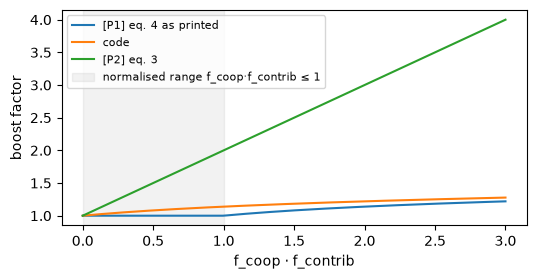

In [48]:
import numpy as np
x = np.linspace(0, 3, 200)
plt.figure(figsize=(6, 2.8))
plt.plot(x, 1 + np.log1p(np.maximum(0, x - 1)) / 5, label="[P1] eq. 4 as printed")
plt.plot(x, 1 + np.log1p(x) / 5, label="code")
plt.plot(x, 1 + x, label="[P2] eq. 3")
plt.axvspan(0, 1, color="grey", alpha=0.1, label="normalised range f_coop·f_contrib ≤ 1")
plt.xlabel("f_coop · f_contrib"); plt.ylabel("boost factor"); plt.legend(fontsize=8); plt.show()

#### [I-43](../issues.md#I-43) · r_res is always −1.5 because the order was overwritten

In [49]:
show("I-43")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | r_res for an order that was filled completely |
| **Expected** | `1.0` |
| **Actual** | `-1.5` |

The reward receives the mutated order (quantity 0) from I-12; r_trade is 0 for the same reason.

<details><summary>Demo code</summary>

```python
@demo(
    "I-43",
    "C2",
    "r_res is always −1.5 because the order was overwritten",
    "r_res for an order that was filled completely",
)
def i43():
    m, grid, dso, _ = matcher()
    b = order("a0", 200.0, 10.0, True)
    submitted = copy.copy(b)
    res = m.match_orders(0, [b, order("a1", 50.0, 10.0, False)], {}, 0.0)
    h = RewardHandler(dso, grid)
    trades = [t for t in res.trades if "a0" in (t.buyer_id, t.seller_id)]
    return (
        h._calculate_resource_allocation_reward(submitted, trades),
        h._calculate_resource_allocation_reward(b, trades),
        "The reward receives the mutated order (quantity 0) from I-12; r_trade is 0 "
        "for the same reason.",
    )
```
</details>

#### [I-45](../issues.md#I-45) · The local-trade weight is overwritten

In [50]:
show("I-45")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | weight of local trades in r_trade (the 'Trade weights' block sets 0.7) |
| **Expected** | `0.7` |
| **Actual** | `0.3` |

_w_local is set again to 0.3 in the 'Contribution weights' block.

<details><summary>Demo code</summary>

```python
@demo(
    "I-45",
    "C2",
    "The local-trade weight is overwritten",
    "weight of local trades in r_trade (the 'Trade weights' block sets 0.7)",
)
def i45():
    m, grid, dso, _ = matcher()
    return (
        0.7,
        RewardHandler(dso, grid)._w_local,
        "_w_local is set again to 0.3 in the 'Contribution weights' block.",
    )
```
</details>

#### [I-47](../issues.md#I-47) · Every agent without trades gets the same fixed reward

In [51]:
show("I-47")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | rewards of two different agents without trades differ |
| **Expected** | `different` |
| **Actual** | `both -4.463` |

Fixed −20·ln(1 + 5/20) before any other term; reachable when q_min = 0 (Case 6).

<details><summary>Demo code</summary>

```python
@demo(
    "I-47",
    "C2",
    "Every agent without trades gets the same fixed reward",
    "rewards of two different agents without trades differ",
)
def i47():
    m, grid, dso, _ = matcher()
    res = m.match_orders(
        0, [order("a0", 200.0, 10.0, True), order("a1", 50.0, 10.0, False)], {}, 0.0
    )
    h = RewardHandler(dso, grid)
    rich = DERAgent("x", 60.0, generation_profile=[50.0], demand_profile=[0.1])
    poor = DERAgent("y", 60.0, generation_profile=[0.1], demand_profile=[50.0])
    r = [
        round(
            float(
                h.calculate_reward(
                    a, order(a.id, 100.0, 5.0, True), res, {}, 10.0, 300.0
                )
            ),
            3,
        )
        for a in (rich, poor)
    ]
    return (
        "different",
        "different" if r[0] != r[1] else f"both {r[0]}",
        "Fixed −20·ln(1 + 5/20) before any other term; reachable when q_min = 0 "
        "(Case 6).",
    )
```
</details>

## Stage D · Level 1, MARL Agents

### D1. Training paradigms

#### [I-59](../issues.md#I-59) · Grouped spaces are sorted, grouped data is not

In [52]:
show("I-59")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | the space in tuple slot 0 belongs to the agent in slot 0 ('b', q_max 30) |
| **Expected** | `b` |
| **Actual** | `a` |

Group order ['b', 'a']; tuple spaces follow sorted keys ['a', 'b'].

<details><summary>Demo code</summary>

```python
@demo(
    "I-59",
    "D1",
    "Grouped spaces are sorted, grouped data is not",
    "the space in tuple slot 0 belongs to the agent in slot 0 ('b', q_max 30)",
)
def i59():
    from src_thesis.marlem.marl.train import GroupedLEM

    g = GroupedLEM(_grouped_env_config())
    slot0_qmax = float(g.action_space["grouped_agents"][0].high[1])
    owner = "b" if slot0_qmax == 30.0 else "a"
    return (
        "b",
        owner,
        f"Group order {g.original_agents_id}; tuple spaces follow sorted keys ['a', "
        "'b'].",
    )
```
</details>

#### [I-62](../issues.md#I-62) · A positive evaluation_duration is rejected

In [53]:
show("I-62")

🔴 **REPRODUCED**

| | |
|---|---|
| **Paper / intent** | RLTrainer(..., evaluation_duration=5) is accepted |
| **Expected** | `accepted` |
| **Actual** | `ValueError` |

The <evaluation_duration> must be a positive integer or 'auto', got <evaluation_duration = 5>.

<details><summary>Demo code</summary>

```python
@demo(
    "I-62",
    "D1",
    "A positive evaluation_duration is rejected",
    "RLTrainer(..., evaluation_duration=5) is accepted",
)
def i62():
    from src_thesis.marlem.marl.train import RLTrainer

    try:
        RLTrainer(_grouped_env_config(), evaluation_duration=5, iters=10)
        return "accepted", "accepted"
    except ValueError as e:
        return "accepted", "ValueError", str(e)
```
</details>